# 02 – Python basics for data work

**Goal:** the core Python you need before working with datasets.

1. Lists and indexing
2. Dictionaries
3. `for` loops and list comprehensions
4. `if` / `elif` / `else`
5. Functions

Each section ends with exercises in their own cells. Solve them yourself, ask for a hint if you're stuck, and send me your solutions for review. The final exercise combines all five topics.

Run the cells top to bottom (**Shift + Enter**). Before saving, check that the notebook still works after **Restart Kernel → Run All**.

## Setup

In [474]:
from rdkit import Chem
from rdkit.Chem import Descriptors, Draw, rdMolDescriptors

## 1. Lists and indexing

A **list** is an ordered, changeable sequence, written with `[ ]`. It can hold any type, mixed.

- Closest equivalents: an R `list()` or vector `c()`, and a MATLAB cell array `{ }`.
- A list is not a numeric vector: `[1, 2] * 2` gives `[1, 2, 1, 2]`, not `[2, 4]`. Vectorized arithmetic comes later with NumPy and pandas.

In [475]:
names = ["ethanol", "benzene", "aspirin", "caffeine", "paracetamol"]
smiles_list = [
    "CCO",
    "c1ccccc1",
    "CC(=O)Oc1ccccc1C(=O)O",
    "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
    "CC(=O)Nc1ccc(O)cc1",
]

len(smiles_list)

5

### Indexing is 0-based

| | Python | R | MATLAB |
|---|---|---|---|
| first element | `x[0]` | `x[1]` | `x(1)` |
| last element | `x[-1]` | `x[length(x)]` | `x(end)` |
| out of range | `IndexError` | `NA` | error |

Negative indices count from the end. Note that `x[-1]` in R means "drop the first element", which is completely different.

In [476]:
print(names[0])    # first
print(names[2])    # third
print(names[-1])   # last
print(names[-2])   # second to last

ethanol
aspirin
paracetamol
caffeine


### Slicing

`x[start:stop]` returns a new list from index `start` up to, but **not including**, `stop`. The number of elements is `stop - start`.

- `names[1:3]` gives elements 1 and 2. In R that's `names[2:3]`, in MATLAB `names(2:3)`.
- If you leave out `start`, the slice begins at the start of the list. If you leave out `stop`, it runs to the end.
- `x[start:stop:step]` takes every `step`-th element, and `x[::-1]` reverses the list.

In [477]:
print(names[1:3])
print(names[:2])     # first two
print(names[3:])     # from index 3 to the end
print(names[::2])    # every second element
print(names[::-1])   # reversed

['benzene', 'aspirin']
['ethanol', 'benzene']
['caffeine', 'paracetamol']
['ethanol', 'aspirin', 'paracetamol']
['paracetamol', 'caffeine', 'aspirin', 'benzene', 'ethanol']


### Changing a list

- `x[i] = value` replaces an element.
- `x.append(value)` adds an element at the end. It changes the list **in place** and returns `None`, so don't write `x = x.append(...)`.

In [478]:
mw_list = [46.07, 78.11]
mw_list.append(180.16)
mw_list[0] = 46.069
print(mw_list)

[46.069, 78.11, 180.16]


**Assignment doesn't copy.** `b = a` makes `b` a second name for the **same** list. In R, `b <- a` followed by a change to `b` leaves `a` unchanged, and MATLAB behaves the same way. Python doesn't. This is what happened with `mols3 = mol3` in notebook 01. Use `.copy()` when you need an independent list.

In [479]:
a = ["CCO", "CO"]
b = a              # same list, two names
b.append("CCC")
print(a)           # a changed too

c = a.copy()       # independent copy
c.append("CCCC")
print(a)
print(c)

['CCO', 'CO', 'CCC']
['CCO', 'CO', 'CCC']
['CCO', 'CO', 'CCC', 'CCCC']


### Tuples

A **tuple** is like a list but can't be changed after creation. It's written with `( )`. Tuples hold fixed groups of values, such as an image size `(300, 300)` or a (name, SMILES) pair. You can **unpack** a tuple into separate variables in one assignment.

In [480]:
pair = ("aspirin", "CC(=O)Oc1ccccc1C(=O)O")
name, smi = pair     # unpacking
print(name)
print(smi)

aspirin
CC(=O)Oc1ccccc1C(=O)O


### Exercise 1.1

Use `names` and indexing (don't type the strings yourself) to get:

1. `"caffeine"`, once with a positive and once with a negative index
2. `["aspirin", "caffeine", "paracetamol"]` with a slice
3. the first three names with a slice

In [481]:
# Exercise 1.1: your code here
# names = ["ethanol", "benzene", "aspirin", "caffeine", "paracetamol"]

print(names[3]) # positive index
print(names[-2]) # negative index
print(names[2:]) # slice from index 2 to the end
print(names[:3]) # slice from the beginning to index 2, index 3 is not included

caffeine
caffeine
['aspirin', 'caffeine', 'paracetamol']
['ethanol', 'benzene', 'aspirin']


### Exercise 1.2

`x = [10, 20, 30, 40, 50]`. **Predict first, then run:** what do `x[1:4]`, `x[-2:]` and `x[4:1]` give?

Then write the Python slice that selects the same elements as `x[2:4]` in R.

In [482]:
# Exercise 1.2: your code here
x = [10, 20, 30, 40, 50]

# Prediction: 
# x[1:4] 20, 30, 40; because last is not included
# x[-2:] 40, 50; 
# x[4:1] nothing. For reverse, it would say x[4:1:-1].

print(x[1:4])
print(x[-2:])
print(x[4:1])

print(x[1:4])

[20, 30, 40]
[40, 50]
[]
[20, 30, 40]


## 2. Dictionaries

A **dict** maps keys to values: `{key: value, ...}`. You look values up by key, not by position. Keys are unique and are usually strings.

| | Python | R | MATLAB |
|---|---|---|---|
| create | `d = {"ethanol": "CCO"}` | `l <- list(ethanol = "CCO")` | `s.ethanol = 'CCO'` |
| access | `d["ethanol"]` | `l[["ethanol"]]` or `l$ethanol` | `s.ethanol` |

MATLAB struct field names must be valid identifiers. Dict keys can be any string, such as `"(-)-menthol"`. `containers.Map` is MATLAB's closer equivalent.

In [483]:
smiles_dict = {
    "ethanol": "CCO",
    "benzene": "c1ccccc1",
    "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
}

print(smiles_dict["aspirin"])

smiles_dict["caffeine"] = "Cn1cnc2c1c(=O)n(C)c(=O)n2C"   # new key: adds an entry
smiles_dict["ethanol"] = "OCC"                           # existing key: overwrites (same molecule, different SMILES)
print(len(smiles_dict))

CC(=O)Oc1ccccc1C(=O)O
4


### Missing keys

`d["missing"]` raises a `KeyError`. There are two safe alternatives:

- `key in d` returns `True` or `False`.
- `d.get(key, default)` returns `default` if the key is absent. Without a default, it returns `None`.

In [484]:
print("aspirin" in smiles_dict)
print("ibuprofen" in smiles_dict)
print(smiles_dict.get("ibuprofen"))
print(smiles_dict.get("ibuprofen", "not found"))

True
False
None
not found


### Keys, values, items

`.keys()`, `.values()` and `.items()` return views of the dict. Wrap them in `list()` when you need a real list. `.items()` yields `(key, value)` tuples, which is why `for name, smi in smiles.items()` works.

In [485]:
print(list(smiles_dict.keys()))
print(list(smiles_dict.values()))
print(list(smiles_dict.items())[:2])   # first two (key, value) pairs

['ethanol', 'benzene', 'aspirin', 'caffeine']
['OCC', 'c1ccccc1', 'CC(=O)Oc1ccccc1C(=O)O', 'Cn1cnc2c1c(=O)n(C)c(=O)n2C']
[('ethanol', 'OCC'), ('benzene', 'c1ccccc1')]


### Nested values

Values can be any type, including lists and other dicts. A dict like the one below describes one record. Later, a pandas DataFrame will hold many such records as rows.

In [486]:
aspirin = {
    "smiles": "CC(=O)Oc1ccccc1C(=O)O",
    "mw": 180.16,
    "targets": ["COX-1", "COX-2"],
}

print(aspirin["targets"][0])   # index into the list stored under "targets"

COX-1


### Exercise 2.1

Create a dict `mw_dict` that maps `"ethanol"`, `"benzene"` and `"aspirin"` to their average MW, calculated with `Descriptors.MolWt`. Write one line per molecule; loops come in the next section.

Then add `"paracetamol"`, and print the MW of benzene with 2 decimals.

In [533]:
# Exercise 2.1: your code here
mw_dict = {
    "ethanol": Descriptors.MolWt(Chem.MolFromSmiles('CCO')),
    "benzene": Descriptors.MolWt(Chem.MolFromSmiles('c1ccccc1')),
    "aspirin": Descriptors.MolWt(Chem.MolFromSmiles('CC(=O)Oc1ccccc1C(=O)O')),
}
mw_dict["paracetamol"] = Descriptors.MolWt(Chem.MolFromSmiles('CC(=O)Nc1ccc(O)cc1'))

print(f"MW of benzene: {mw_dict["benzene"]:.2f}")


MW of benzene: 78.11


### Exercise 2.2

**Predict first, then run:**

1. `smiles_dict[0]`
2. `smiles_dict.get("menthol", "unknown")`

Why does the first one fail, even though `smiles_dict` has entries?

In [733]:
# Exercise 2.2: your code here
# Prediction: 
# 1. It should fail. For lists, it'll look for the first entry but for dictionaries, it will look for the key 0. Our dictionary does not have the key "0", therefore will give an error.
# list(smiles_dict.keys()) shows the keys, which are "ethanol", "benzene", "aspirin", and "caffeine". The first entry is "ethanol" and the last entry is "caffeine". The second entry is "benzene" and the third entry is "aspirin".
# 2. This will check whether menthol is a key in smiles_dict. If yes, it'll show the value which in this case is the SMILES, otherwise it does not print "None" which is the standard solution, but it will say "unknown"


#smiles_dict[0]
smiles_dict.get("menthol", "unknown")

'unknown'

## 3. `for` loops and list comprehensions

A `for` loop runs over the items of a sequence directly. The loop body is indented, with no braces and no `end`.

- Looping over a list gives the elements.
- Looping over a dict gives the keys.
- Looping over `d.items()` gives `(key, value)` pairs.

In [734]:
for smi in smiles_list:
    mol = Chem.MolFromSmiles(smi)
    print(smi, mol.GetNumAtoms())   # heavy atoms only, because H atoms are implicit

CCO 3
c1ccccc1 6
CC(=O)Oc1ccccc1C(=O)O 13
Cn1cnc2c1c(=O)n(C)c(=O)n2C 14
CC(=O)Nc1ccc(O)cc1 11


### `enumerate` and `zip`

- `enumerate(x)` yields `(index, item)` pairs, with the index starting at 0. Use it when you need the position too.
- `zip(a, b)` pairs up elements of two lists, position by position.

`for i in range(len(x)):` also works, but it isn't idiomatic Python. `range(n)` gives 0 to n−1, like `0:(n-1)` in R.

In [735]:
for i, name in enumerate(names):
    print(i, name)

0 ethanol
1 benzene
2 aspirin
3 caffeine
4 paracetamol


In [736]:
for name, smi in zip(names, smiles_list):
    mw = Descriptors.MolWt(Chem.MolFromSmiles(smi))
    print(f"{name:<12} {mw:>7.2f}")

ethanol        46.07
benzene        78.11
aspirin       180.16
caffeine      194.19
paracetamol   151.16


To build a list in a loop, start with an empty list and `append` to it:

In [737]:
mws = []
for smi in smiles_list:
    mws.append(Descriptors.MolWt(Chem.MolFromSmiles(smi)))

print(mws)

[46.069, 78.11399999999999, 180.15899999999996, 194.194, 151.165]


Values like `78.11399999999999` come from binary floating-point arithmetic. R and MATLAB store the same values but show fewer digits by default. Round only for display, with `round(x, 2)` or `f"{x:.2f}"`.

### List comprehensions

`[expression for item in iterable]` builds the same list in one line. Read it as "the expression, for each item". Closest equivalents: `sapply(x, f)` in R, `arrayfun` / `cellfun` in MATLAB.

Add `if condition` at the end to keep only the items for which the condition is true.

In [738]:
mws = [Descriptors.MolWt(Chem.MolFromSmiles(smi)) for smi in smiles_list]
print(mws)

heavier = [name for name, mw in zip(names, mws) if mw > 150]
print(heavier)

[46.069, 78.11399999999999, 180.15899999999996, 194.194, 151.165]
['aspirin', 'caffeine', 'paracetamol']


A **dict comprehension** works the same way, with `key: value` as the expression:

In [739]:
mw_by_name = {name: round(mw, 2) for name, mw in zip(names, mws)}
mw_by_name

{'ethanol': 46.07,
 'benzene': 78.11,
 'aspirin': 180.16,
 'caffeine': 194.19,
 'paracetamol': 151.16}

Use a comprehension when each element comes from one short expression. Use a regular loop when the body has several steps, prints something, or handles errors.

A list of `Mol` objects can be passed straight to the drawing function:

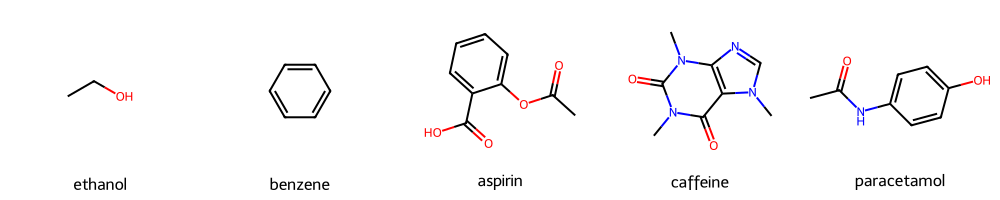

In [740]:
mols = [Chem.MolFromSmiles(smi) for smi in smiles_list]
Draw.MolsToGridImage(mols, legends=names, molsPerRow=5, subImgSize=(200, 200))

### Exercise 3.1

Write a `for` loop over `smiles_dict.items()` that prints each name and its number of heavy atoms, one molecule per line, with names left-aligned in a column 12 characters wide.

In [741]:
# Exercise 3.1: your code here

### Exercise 3.2

Write **one** list comprehension that returns the names (from `names`) of all molecules whose SMILES contains a lowercase `"c"` (aromatic carbon). Hint: `"c" in smi` tests whether a substring occurs, and `zip` gives you names and SMILES together.

Then think about it: why is searching the SMILES string a fragile way to detect aromaticity? Give an example SMILES that would fool it, in either direction.

In [742]:
# Exercise 3.2: your code here

## 4. `if` / `elif` / `else`

```python
if condition:
    ...
elif other_condition:
    ...
else:
    ...
```

- `elif` is R's `else if` and MATLAB's `elseif`. Each condition line ends with a colon, and the block is indented.
- The comparison operators are `==`, `!=`, `<`, `<=`, `>` and `>=`.
- The logical operators are the words `and`, `or` and `not`, not `&&`, `||` and `!`.
- Use `is None` to test for `None`.

In [743]:
mw = Descriptors.MolWt(Chem.MolFromSmiles("Cn1cnc2c1c(=O)n(C)c(=O)n2C"))

if mw < 100:
    size = "small"
elif mw < 300:
    size = "medium"
else:
    size = "large"

print(f"caffeine: {mw:.2f} -> {size}")

caffeine: 194.19 -> medium


Conditions are checked from top to bottom, and only the first true branch runs. So the `elif mw < 300` branch only runs when `mw >= 100`.

### Skipping invalid input

`Chem.MolFromSmiles` returns `None` for invalid SMILES. Inside a loop, `continue` jumps straight to the next item. It's the equivalent of `next` in R and `continue` in MATLAB.

In [744]:
test_smiles = ["CCO", "C1CC", "c1ccccc1", "not_a_smiles"]

for smi in test_smiles:
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        print(f"skipped: {smi}")
        continue
    print(f"{smi}: {Descriptors.MolWt(mol):.2f}")

CCO: 46.07
skipped: C1CC
c1ccccc1: 78.11
skipped: not_a_smiles


[22:53:57] SMILES Parse Error: unclosed ring for input: 'C1CC'
[22:53:57] SMILES Parse Error: syntax error while parsing: not_a_smiles
[22:53:57] SMILES Parse Error: check for mistakes around position 3:
[22:53:57] not_a_smiles
[22:53:57] ~~^
[22:53:57] SMILES Parse Error: Failed parsing SMILES 'not_a_smiles' for input: 'not_a_smiles'


RDKit also prints its own `SMILES Parse Error` messages, often highlighted in red. These are log messages, not exceptions, so the loop keeps running.

### Truthiness

Inside an `if`, the following all count as false: an empty list `[]`, an empty dict `{}`, `0`, an empty string `""`, and `None`. So `if not found:` means "if the list is empty". R would need `if (length(found) == 0)`.

In [745]:
found = []
if not found:
    print("no molecules found")

no molecules found


### Exercise 4.1

Loop over `names` and `smiles_list` together. For each molecule, print its name followed by `passes` or `fails` for this rule: **MW ≤ 180 and at least one ring**.

`rdMolDescriptors.CalcNumRings(mol)` returns the number of rings. Which molecules fail, and for which reason?

In [746]:
# Exercise 4.1: your code here

### Exercise 4.2

**Predict first, then run** for `x = 150`, `x = 80` and `x = 30`:

```python
if x > 100 and x < 200:
    print("A")
elif x > 50 or x == 30:
    print("B")
else:
    print("C")
```

In [747]:
# Exercise 4.2: your code here

## 5. Functions

```python
def name(arg1, arg2):
    """Docstring: what the function does."""
    ...
    return result
```

- **Python needs an explicit `return`.** R returns the last expression automatically. A Python function without `return` returns `None`.
- **Functions can be defined anywhere.** MATLAB puts functions in their own files or at the end of a script. In Python, you can define them anywhere, including in a notebook cell.
- **Docstrings.** The string on the first line of the body is the docstring, and `help(name)` displays it.

In [748]:
def mol_weight(smiles):
    """Return the average molecular weight for a SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    return Descriptors.MolWt(mol)


print(mol_weight("CCO"))
help(mol_weight)

46.069
Help on function mol_weight in module __main__:

mol_weight(smiles)
    Return the average molecular weight for a SMILES string.



### Default and keyword arguments

- An argument with a default value (`exact=False`) is optional.
- Calls can pass arguments by position or by name, as in R.
- `return` ends the function immediately. Here, an early `return None` handles invalid input before the rest runs.
- Defining a function with the same name again replaces the old definition.

In [749]:
def mol_weight(smiles, exact=False):
    """Return the average (default) or monoisotopic mass of a SMILES string, or None if it is invalid."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    if exact:
        return Descriptors.ExactMolWt(mol)
    return Descriptors.MolWt(mol)


print(mol_weight("CCO"))
print(mol_weight("CCO", exact=True))
print(mol_weight("C1CC"))

46.069
46.041864812
None


[22:53:57] SMILES Parse Error: unclosed ring for input: 'C1CC'


### Returning several values

To return several values, return a tuple and unpack it at the call site. This is like `[a, b] = f(x)` in MATLAB.

In [750]:
def formula_and_mw(smiles):
    """Return the molecular formula and average MW of a SMILES string."""
    mol = Chem.MolFromSmiles(smiles)
    return rdMolDescriptors.CalcMolFormula(mol), Descriptors.MolWt(mol)


formula, mw = formula_and_mw("CC(=O)Oc1ccccc1C(=O)O")
print(formula, round(mw, 2))

C9H8O4 180.16


**Scope:** variables created inside a function are local, so they don't exist after the call. This works as in R and MATLAB. A function *can* read notebook variables from outside, but passing everything in as arguments makes it predictable and reusable.

### Exercise 5.1

Write a function `num_heavy_atoms(smiles)` that returns the number of heavy atoms, or `None` for an invalid SMILES. Include a docstring. Test it with `"CCO"`, caffeine, and `"C1CC"`.

In [751]:
# Exercise 5.1: your code here

### Exercise 5.2

Write a function `size_class(mw, cutoff=150)` that returns `"small"` if `mw` is below `cutoff`, and `"large"` otherwise. Call it once with the default cutoff and once with `cutoff=200` given as a keyword argument, using aspirin's MW both times. Why do the two calls give different results?

In [752]:
# Exercise 5.2: your code here

## 6. Final exercise: putting it together

Write a function `mw_table(molecules)` that:

1. takes a **list of (name, SMILES) tuples**. A SMILES string doesn't contain a name, so each SMILES comes paired with one;
2. returns a **dict** that maps name → average MW, rounded to 2 decimals;
3. **skips invalid SMILES** and prints one message for each skipped entry, saying which name failed;
4. has a docstring.

Test it on `test_molecules` below. The result should have **4 entries**, because two of the SMILES are broken.

**Bonus:**

- **(a)** Add an argument `exact=False` that switches to the monoisotopic mass.
- **(b)** Print the result as a table sorted by MW, from lightest to heaviest. Look up how `sorted()` and its `key=` argument work.

In [753]:
test_molecules = [
    ("ethanol", "CCO"),
    ("aspirin", "CC(=O)Oc1ccccc1C(=O)O"),
    ("broken ring", "C1CC"),
    ("caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
    ("unclosed branch", "CC(=O"),
    ("(-)-menthol", "CC(C)[C@@H]1CC[C@@H](C)C[C@H]1O"),
]

In [754]:
# Final exercise: your code here